# Texas Senate: Kalshi + Polymarket

Run **all cells in order**. The result is one DataFrame, `df`, with exactly:

`time`, `Khalsi-Talarico`, `Khalsi-Paxton`, `Polymarket-Talarico`, `Polymarket-Paxton`.

The column spelling **Khalsi** follows the requested output; the source is Kalshi.
Prices are YES prices in dollars, from 0 to 1 (0.65 = approximately 65%). Defaults
are the last seven days and one row per completed UTC minute. Neither API needs a
key for these REST reads. No original notebook or script is needed.

**Time alignment:** `time` is the UTC minute **end**. Kalshi's candle-end times are
kept. Polymarket aggregate timestamps are bucket starts: their served width
(60 seconds) is added to reach the bucket end. Exact terminal ticks have zero
width and are assigned to the first minute boundary at or after their time.
When several observations map to one minute, the latest source timestamp wins.
This aligns the time periods without treating bucket starts as candle ends.

**Missing data:** gaps remain `NaN`. Set `FORWARD_FILL = True` to carry the last
known price through later gaps; leading gaps remain missing. Kalshi uses the
reported trade close, falling back to its API-provided previous trade price when
no close exists. Polymarket retains its API's sampled price definition. Matching
times does not turn the source prices into identical measures.

Polymarket documents at least seven days of minute availability; older requested
windows can be sparse or empty. Labels refer to the current party nominees.

Sources: [Kalshi event candles](https://docs.kalshi.com/api-reference/events/get-event-candlesticks),
[Polymarket history](https://docs.polymarket.com/api-reference/markets/get-a-tokens-price-history),
[Polymarket timestamp semantics](https://data-api.polymarket.com/v2/openapi.json).

Validated with sample API responses; a live pull could not be checked in the
authoring session because direct API requests were blocked. No sample prices
are embedded in this notebook.


In [1]:
# Install missing packages into this Jupyter kernel.
import importlib.util
missing = [name for name in ("pandas", "matplotlib")
           if importlib.util.find_spec(name) is None]
if missing:
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing))

import json
import math
import time
import textwrap
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import pandas as pd
import numpy as np

DAYS = 7
FORWARD_FILL = False  # True carries the last available price through later gaps.
KALSHI_EVENT = "SENATETX-26"
POLYMARKET_EVENT = "texas-senate-election-winner"
KALSHI_BASE = "https://external-api.kalshi.com/trade-api/v2"
POLYMARKET_BASE = "https://data-api.polymarket.com/v2"
PRICE_COLUMNS = ["Khalsi-Talarico", "Khalsi-Paxton",
                 "Polymarket-Talarico", "Polymarket-Paxton"]


In [2]:
def get_json(url, params=None):
    """Retry temporary failures; report permanent errors with their details."""
    if params:
        url += "?" + urlencode(params)
    request = Request(url, headers={
        "Accept": "application/json",
        "User-Agent": "texas-senate-price-history/1.0",
    })
    for attempt in range(5):
        try:
            with urlopen(request, timeout=45) as response:
                return json.load(response)
        except HTTPError as exc:
            detail = exc.read().decode("utf-8", errors="replace")[:600]
            if exc.code not in (429, 500, 502, 503, 504) or attempt == 4:
                raise RuntimeError(f"HTTP {exc.code} from {url}: {detail}") from exc
            try:
                delay = float(exc.headers.get("Retry-After", 2 ** attempt))
            except (TypeError, ValueError):
                delay = 2 ** attempt
            # Avoid silently ignoring an unusually long server retry request.
            if not math.isfinite(delay) or delay > 60:
                raise RuntimeError("Server requested a long delay; try again later.") from exc
            time.sleep(max(0, delay))
        except (URLError, TimeoutError) as exc:
            if attempt == 4:
                raise RuntimeError(f"Could not reach {url}: {exc}") from exc
            time.sleep(2 ** attempt)


def price_or_missing(value):
    if value is None or value == "":
        return None
    price = float(value)
    if not math.isfinite(price) or not 0 <= price <= 1:
        raise ValueError(f"Expected a dollar price between 0 and 1; received {value!r}")
    return price


def minute_series(rows, start, end, polymarket=False):
    """Map one source to UTC minute-end times; keep the latest observation."""
    if not rows:
        return pd.Series(dtype="float64", index=pd.DatetimeIndex([], tz="UTC", name="time"))
    frame = pd.DataFrame(rows)
    frame["price"] = pd.to_numeric(frame["price"], errors="raise")
    frame = frame.dropna(subset=["price"]).sort_values("timestamp", kind="stable")
    observed = pd.to_datetime(frame["timestamp"], unit="s", utc=True)
    if polymarket:
        # Aggregates report bucket START; exact ticks report their own instant.
        available = observed + pd.to_timedelta(frame["resolution_seconds"], unit="s")
        frame["time"] = available.dt.ceil("min")
    else:
        # Kalshi reports candle END. Do not shift these timestamps by a minute.
        if (observed != observed.dt.floor("min")).any():
            raise ValueError("Kalshi returned a candle end outside a minute boundary.")
        frame["time"] = observed
    frame = frame[(frame["time"] > start) & (frame["time"] <= end)]
    result = frame.drop_duplicates("time", keep="last").set_index("time")["price"]
    return result.astype(float).sort_index()


def fetch_kalshi(start, end):
    """Fetch the two party contracts, using candle close/previous trade prices."""
    event = get_json(f"{KALSHI_BASE}/events/{KALSHI_EVENT}")
    series_ticker = event["event"]["series_ticker"]
    tickers = {f"{KALSHI_EVENT}-D": "Khalsi-Talarico",
               f"{KALSHI_EVENT}-R": "Khalsi-Paxton"}
    available = {market["ticker"] for market in event["markets"]}
    if not set(tickers).issubset(available):
        raise RuntimeError("The expected Democratic/Republican Kalshi contracts were not found.")
    rows = {column: [] for column in tickers.values()}
    left, finish = int(start.timestamp()), int(end.timestamp())
    while left < finish:
        right = min(left + 86400, finish)
        data = get_json(
            f"{KALSHI_BASE}/series/{series_ticker}/events/{KALSHI_EVENT}/candlesticks",
            {"start_ts": left + 1, "end_ts": right, "period_interval": 1},
        )
        market_tickers = data["market_tickers"]
        candle_arrays = data["market_candlesticks"]
        if len(market_tickers) != len(candle_arrays):
            raise RuntimeError("Kalshi returned mismatched ticker and candle arrays.")
        # Continue from any server-shortened window instead of dropping its tail.
        adjusted = data.get("adjusted_end_ts")
        served_end = min(right, int(adjusted)) if adjusted else right
        if served_end <= left:
            raise RuntimeError("Kalshi returned a time window that made no progress.")
        for ticker, candles in zip(market_tickers, candle_arrays):
            if ticker not in tickers:
                continue
            for candle in candles:
                timestamp = int(candle["end_period_ts"])
                if not left < timestamp <= served_end:
                    continue
                values = candle.get("price") or {}
                value = values.get("close_dollars")
                if value is None or value == "":
                    value = values.get("previous_dollars")
                rows[tickers[ticker]].append({"timestamp": timestamp,
                                               "price": price_or_missing(value)})
        left = served_end
    return {name: minute_series(points, start, end) for name, points in rows.items()}


def fetch_polymarket(start, end):
    """Discover YES tokens, then request 60-second history with cursor paging."""
    event = get_json("https://gamma-api.polymarket.com/events/slug/" + POLYMARKET_EVENT)
    targets = {
        "will-the-democrats-win-the-texas-senate-race-in-2026": "Polymarket-Talarico",
        "will-the-republicans-win-the-texas-senate-race-in-2026": "Polymarket-Paxton",
    }
    tokens = {}
    for market in event["markets"]:
        if market.get("slug") not in targets:
            continue
        outcomes, token_ids = market["outcomes"], market["clobTokenIds"]
        outcomes = json.loads(outcomes) if isinstance(outcomes, str) else outcomes
        token_ids = json.loads(token_ids) if isinstance(token_ids, str) else token_ids
        if len(outcomes) != len(token_ids):
            raise RuntimeError("Polymarket returned mismatched outcomes and token IDs.")
        yes_indices = [i for i, outcome in enumerate(outcomes) if outcome.lower() == "yes"]
        if len(yes_indices) != 1:
            raise RuntimeError("Expected exactly one YES outcome per Polymarket contract.")
        tokens[targets[market["slug"]]] = str(token_ids[yes_indices[0]])
    if set(tokens) != set(targets.values()):
        raise RuntimeError("The two expected Polymarket YES tokens were not found.")
    result = {}
    begin, finish = int(start.timestamp()), int(end.timestamp())
    for name, token_id in tokens.items():
        points = {}
        for left in range(begin, finish, 12 * 3600):
            right = min(left + 12 * 3600, finish)
            params = {"token_id": token_id, "start": left, "end": right,
                      "bucket_seconds": 60, "limit": 10000}
            seen_cursors = set()
            while True:
                page = get_json(f"{POLYMARKET_BASE}/prices-history", params)
                if not isinstance(page.get("data"), list):
                    raise RuntimeError("Polymarket returned no price-history data array.")
                for point in page["data"]:
                    timestamp = int(point["timestamp"])
                    resolution = int(point["resolution_seconds"])
                    if resolution not in (0, 60):
                        raise RuntimeError(f"Expected 60-second history; got {resolution} seconds.")
                    if resolution == 60 and timestamp % 60:
                        raise RuntimeError("Polymarket returned a bucket outside the UTC minute grid.")
                    if begin <= timestamp < finish:
                        points[(timestamp, resolution)] = {
                            "timestamp": timestamp, "resolution_seconds": resolution,
                            "price": price_or_missing(point["price"]),
                        }
                paging = page.get("pagination")
                if not isinstance(paging, dict) or "next_cursor" not in paging:
                    raise RuntimeError("Polymarket pagination metadata is missing.")
                cursor = paging["next_cursor"]
                if cursor is None:
                    if paging.get("has_more"):
                        raise RuntimeError("Polymarket indicates more data but returned no cursor.")
                    break
                if not isinstance(cursor, str) or not cursor or cursor in seen_cursors:
                    raise RuntimeError("Polymarket returned an invalid or repeated cursor.")
                seen_cursors.add(cursor)
                params = {**params, "cursor": cursor}
        result[name] = minute_series(list(points.values()), start, end, polymarket=True)
    return result


def build_dataframe(start, end, forward_fill=False):
    """Return exactly one UTC time column and the four requested price columns."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start.tzinfo is None or end.tzinfo is None:
        raise ValueError("Use timezone-aware start/end timestamps.")
    start, end = start.tz_convert("UTC"), end.tz_convert("UTC")
    if start != start.floor("min") or end != end.floor("min") or end <= start:
        raise ValueError("Use minute-aligned timestamps with end after start.")
    print("Fetching Kalshi...", flush=True)
    series = fetch_kalshi(start, end)
    print("Fetching Polymarket...", flush=True)
    series.update(fetch_polymarket(start, end))
    grid = pd.date_range(start + pd.Timedelta(minutes=1), end, freq="min", name="time")
    frame = pd.DataFrame({name: series[name].reindex(grid) for name in PRICE_COLUMNS}, index=grid)
    empty = frame.columns[frame.isna().all()].tolist()
    if empty:
        raise RuntimeError("No observations returned for: " + ", ".join(empty))
    if forward_fill:
        frame = frame.ffill()  # Never backfill from future observations.
    return frame.reset_index()[["time", *PRICE_COLUMNS]]


In [3]:
# Create the consolidated DataFrame using one shared time window.
if not isinstance(DAYS, int) or not 1 <= DAYS <= 15:
    raise ValueError("DAYS must be an integer from 1 to 15; recent minute coverage is best within 7 days.")
end = pd.Timestamp.now(tz="UTC").floor("min")
start = end - pd.Timedelta(days=DAYS)
print(f"UTC minute-end window: {start} (exclusive) to {end} (inclusive)")
df = build_dataframe(start, end, forward_fill=FORWARD_FILL)
print(f"{len(df):,} rows; prices are on the 0-1 dollar scale.")
print("Missing rows by price column:\n" + df[PRICE_COLUMNS].isna().sum().to_string())
display(df.head(10))


UTC minute-end window: 2026-10-20 13:47:00+00:00 (exclusive) to 2026-10-27 13:47:00+00:00 (inclusive)
Fetching Kalshi...
Fetching Polymarket...
10,080 rows; prices are on the 0-1 dollar scale.
Missing rows by price column:
Khalsi-Talarico        3296
Khalsi-Paxton          2162
Polymarket-Talarico       5
Polymarket-Paxton         5


,time,Khalsi-Talarico,Khalsi-Paxton,Polymarket-Talarico,Polymarket-Paxton
0,2026-10-20 13:48:00+00:00,NaN,0.38,0.625,0.375
1,2026-10-20 13:49:00+00:00,NaN,0.38,0.625,0.375
2,2026-10-20 13:50:00+00:00,0.63,0.38,0.625,0.375
3,2026-10-20 13:51:00+00:00,0.63,0.38,0.625,0.375
4,2026-10-20 13:52:00+00:00,0.63,0.38,0.625,0.375
5,2026-10-20 13:53:00+00:00,0.63,NaN,0.625,0.375
6,2026-10-20 13:54:00+00:00,NaN,0.38,0.625,0.375
7,2026-10-20 13:55:00+00:00,0.63,0.38,0.625,0.375
8,2026-10-20 13:56:00+00:00,0.63,0.38,0.625,0.375
9,2026-10-20 13:57:00+00:00,0.63,0.38,0.625,0.375


## Optional: plot or export

The next cells use the same consolidated `df`. The plot shows prices in cents.
The CSV retains dollar prices and explicit UTC offsets.


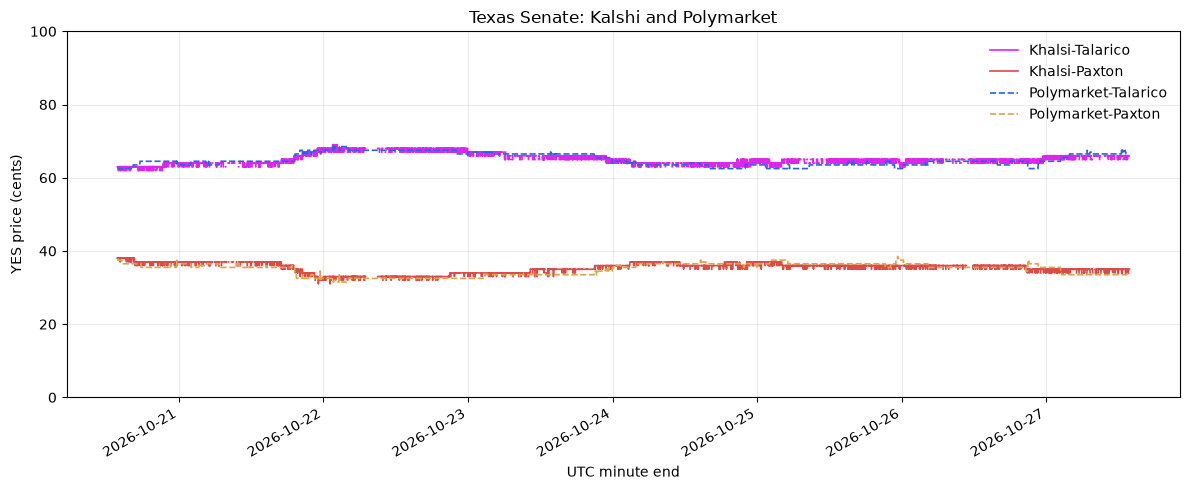

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 5))
styles = {
    "Khalsi-Talarico": ("#de25eb", "-"),
    "Khalsi-Paxton": ("#dc4b47", "-"),
    "Polymarket-Talarico": ("#2563eb", "--"),
    "Polymarket-Paxton": ("#dca547", "--"),
}
for column, (color, linestyle) in styles.items():
    ax.plot(df["time"], df[column] * 100, label=column,
            color=color, linestyle=linestyle, linewidth=1.2)
ax.set(title="Texas Senate: Kalshi and Polymarket", xlabel="UTC minute end",
       ylabel="YES price (cents)", ylim=(0, 100))
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [5]:
# Because on Polymarket you only get odds with two decimal places we have to round up
df["Polymarket-Paxton"] = np.ceil(df["Polymarket-Paxton"] * 100) / 100
df["Polymarket-Talarico"] = np.ceil(df["Polymarket-Talarico"] * 100) / 100

In [6]:
# Going through all betting combinations
df["Khalsi-Paxton and Khalshi-Talarico"] = df["Khalsi-Paxton"] + df["Khalsi-Talarico"]
df["Polymarket-Paxton and Polymarket-Talarico"] = df["Polymarket-Paxton"] + df["Polymarket-Talarico"]
df["Khalsi-Paxton and Polymarket-Talarico"] = df["Khalsi-Paxton"] + df["Polymarket-Talarico"]
df["Polymarket-Paxton and Khalsi-Talarico"] = df["Polymarket-Paxton"] + df["Khalsi-Talarico"]

df

,time,Khalsi-Talarico,Khalsi-Paxton,Polymarket-Talarico,Polymarket-Paxton,Khalsi-Paxton and Khalshi-Talarico,Polymarket-Paxton and Polymarket-Talarico,Khalsi-Paxton and Polymarket-Talarico,Polymarket-Paxton and Khalsi-Talarico
0,2026-10-20 13:48:00+00:00,NaN,0.38,0.63,0.38,NaN,1.01,1.01,NaN
1,2026-10-20 13:49:00+00:00,NaN,0.38,0.63,0.38,NaN,1.01,1.01,NaN
2,2026-10-20 13:50:00+00:00,0.63,0.38,0.63,0.38,1.01,1.01,1.01,1.01
3,2026-10-20 13:51:00+00:00,0.63,0.38,0.63,0.38,1.01,1.01,1.01,1.01
4,2026-10-20 13:52:00+00:00,0.63,0.38,0.63,0.38,1.01,1.01,1.01,1.01
...,...,...,...,...,...,...,...,...,...
10075,2026-10-27 13:43:00+00:00,0.66,0.35,NaN,NaN,1.01,NaN,NaN,NaN
10076,2026-10-27 13:44:00+00:00,NaN,0.35,NaN,NaN,NaN,NaN,NaN,NaN
10077,2026-10-27 13:45:00+00:00,0.66,0.35,NaN,NaN,1.01,NaN,NaN,NaN
10078,2026-10-27 13:46:00+00:00,NaN,0.35,NaN,NaN,NaN,NaN,NaN,NaN


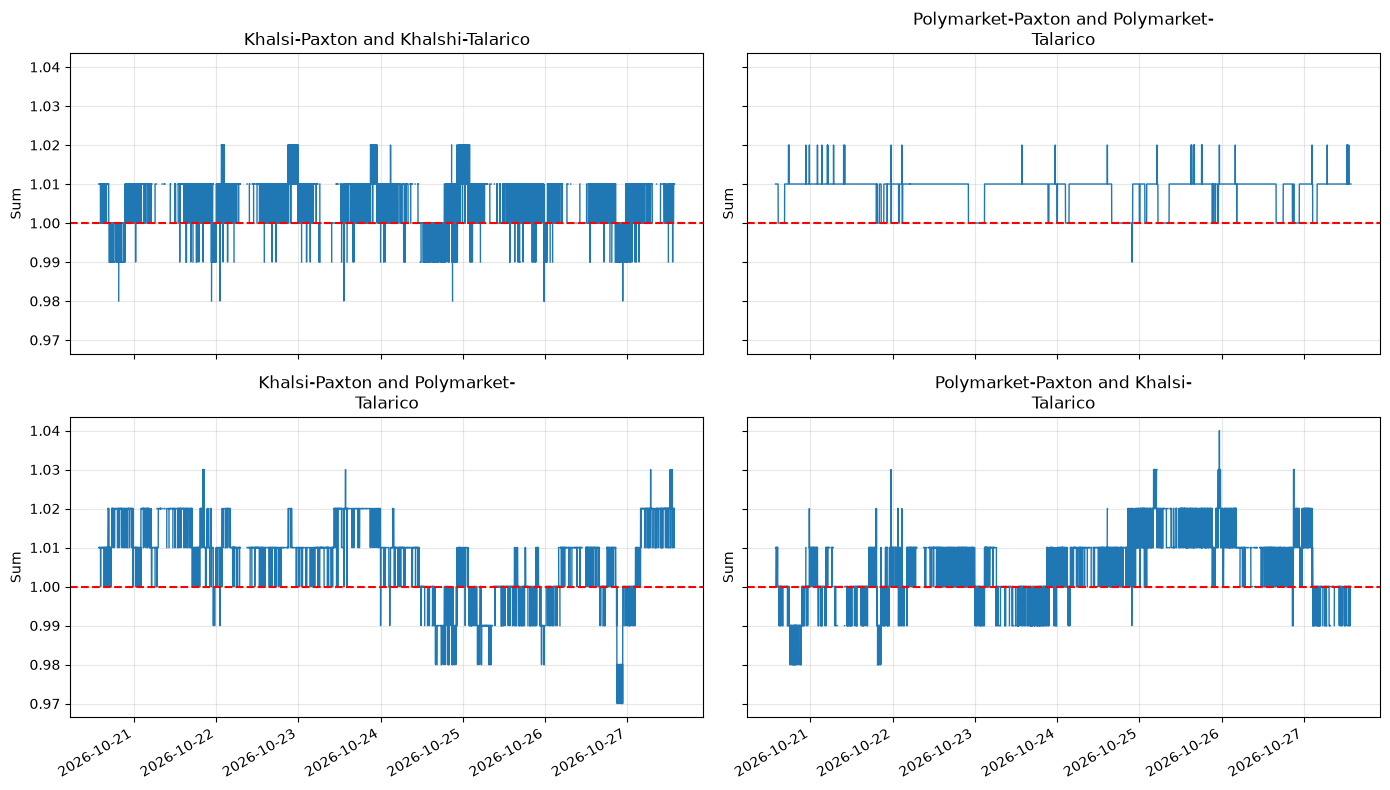

In [7]:
time = pd.to_datetime(df["time"])
cols = df.columns[-4:]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

for ax, col in zip(axes.flat, cols):
    ax.plot(time, df[col], linewidth=1)
    ax.axhline(y=1, color="red", linestyle="--")
    ax.set_title(textwrap.fill(col, width=35))
    ax.set_ylabel("Sum")
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [12]:
analysis = (df.iloc[:, -4:] < 1).sum().to_frame(name="Times the sum is below 1")

def average_rows_to_above(series):
    start = None
    durations = []

    for row, value in enumerate(series):
        if pd.isna(value):
            continue

        if start is None and value < 1:
            start = row
        elif start is not None and value > 1:
            durations.append(row - start)
            start = None

    return np.mean(durations) if durations else np.nan

cols = df.iloc[:, -4:]

analysis = (cols < 1).sum().to_frame(name="Count below 1")
analysis["Average minutes to get back above 1"] = cols.apply(average_rows_to_above)

analysis

,Count below 1,Average minutes to get back above 1
Khalsi-Paxton and Khalshi-Talarico,321,15.019231
Polymarket-Paxton and Polymarket-Talarico,10,16.000000
Khalsi-Paxton and Polymarket-Talarico,782,142.444444
Polymarket-Paxton and Khalsi-Talarico,646,104.730769


### Exporting

In [8]:
export_stamp = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S_%fZ")
csv_path = Path(f"texas_senate_consolidated_{export_stamp}.csv")
df.to_csv(csv_path, index=False, mode="x")
print(f"Saved {csv_path.resolve()}")


Saved C:\Users\Leo\Downloads\texas_senate_consolidated_20261027T134737_394618Z.csv
